### Step 1: Load and Explore the IPL Dataset
We will first load the dataset `/content/IPL IMB381IPL2013.csv` and inspect its columns and data types.

In [1]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('/content/IPL IMB381IPL2013.csv')

# Display information and the first few rows
display(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 26 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sl.NO.         130 non-null    int64  
 1   PLAYER NAME    130 non-null    object 
 2   AGE            130 non-null    int64  
 3   COUNTRY        130 non-null    object 
 4   TEAM           130 non-null    object 
 5   PLAYING ROLE   130 non-null    object 
 6   T-RUNS         130 non-null    int64  
 7   T-WKTS         130 non-null    int64  
 8   ODI-RUNS-S     130 non-null    int64  
 9   ODI-SR-B       130 non-null    float64
 10  ODI-WKTS       130 non-null    int64  
 11  ODI-SR-BL      130 non-null    float64
 12  CAPTAINCY EXP  130 non-null    int64  
 13  RUNS-S         130 non-null    int64  
 14  HS             130 non-null    int64  
 15  AVE            130 non-null    float64
 16  SR-B           130 non-null    float64
 17  SIXERS         130 non-null    int64  
 18  RUNS-C    

None

,Sl.NO.,PLAYER NAME,AGE,COUNTRY,TEAM,PLAYING ROLE,T-RUNS,T-WKTS,ODI-RUNS-S,ODI-SR-B,...,SR-B,SIXERS,RUNS-C,WKTS,AVE-BL,ECON,SR-BL,AUCTION YEAR,BASE PRICE,SOLD PRICE
0,1,"Abdulla, YA",2,SA,KXIP,Allrounder,0,0,0,0.00,...,0.00,0,307,15,20.47,8.90,13.93,2009,50000,50000
1,2,Abdur Razzak,2,BAN,RCB,Bowler,214,18,657,71.41,...,0.00,0,29,0,0.00,14.50,0.00,2008,50000,50000
2,3,"Agarkar, AB",2,IND,KKR,Bowler,571,58,1269,80.62,...,121.01,5,1059,29,36.52,8.81,24.90,2008,200000,350000
3,4,"Ashwin, R",1,IND,CSK,Bowler,284,31,241,84.56,...,76.32,0,1125,49,22.96,6.23,22.14,2011,100000,850000
4,5,"Badrinath, S",2,IND,CSK,Batsman,63,0,79,45.93,...,120.71,28,0,0,0.00,0.00,0.00,2011,100000,800000


### Step 2: Correlation Matrix and Heatmap of Numeric Features
We will extract all numeric features, calculate their pairwise correlation, and visualize them using a seaborn heatmap.

Numeric columns found: ['Sl.NO.', 'AGE', 'T-RUNS', 'T-WKTS', 'ODI-RUNS-S', 'ODI-SR-B', 'ODI-WKTS', 'ODI-SR-BL', 'CAPTAINCY EXP', 'RUNS-S', 'HS', 'AVE', 'SR-B', 'SIXERS', 'RUNS-C', 'WKTS', 'AVE-BL', 'ECON', 'SR-BL', 'AUCTION YEAR', 'BASE PRICE', 'SOLD PRICE']


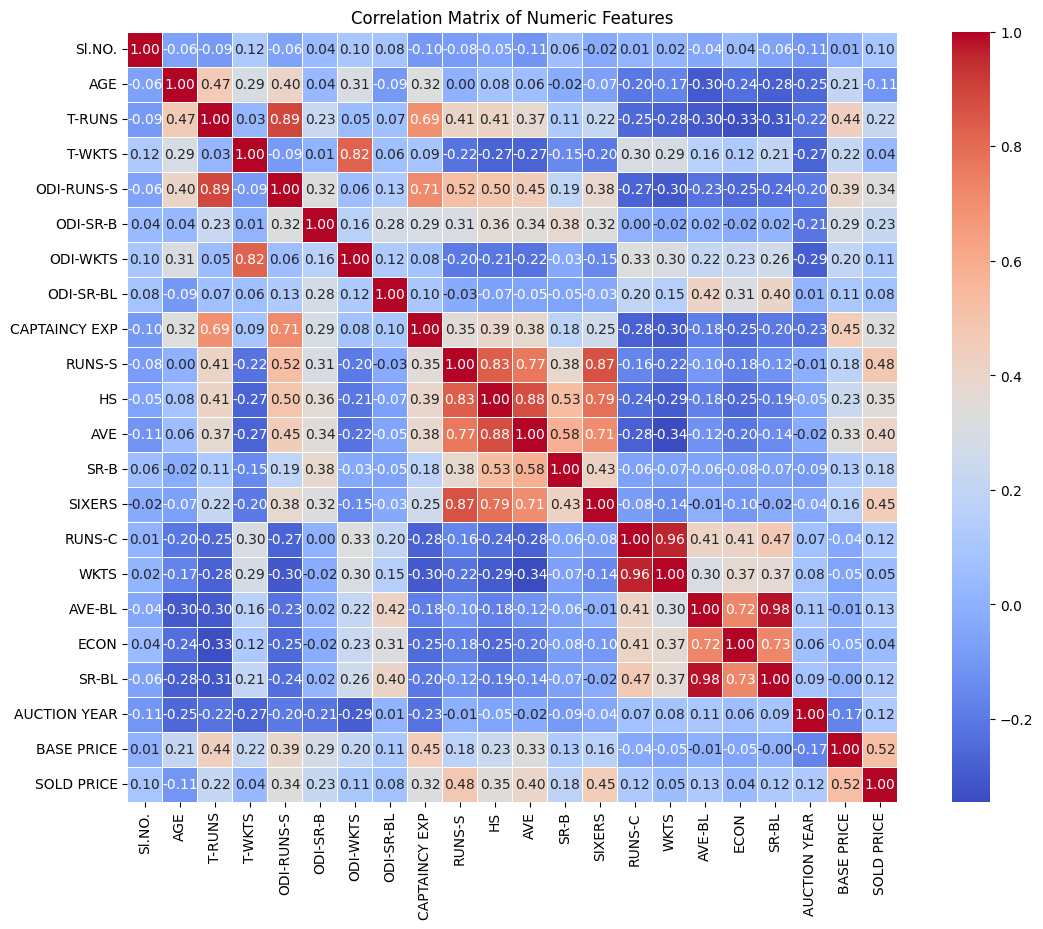

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns found:", numeric_cols)

# Calculate correlation matrix
corr_matrix = df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

### Step 3: Train-Test Split and Regression Model
We will preprocess the data (e.g., dropping non-predictive ID columns, handling missing values, and encoding categorical columns), split the dataset, build a linear regression model, and compute the train and test RMSE.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Drop identifier/non-predictive columns if they exist
cols_to_drop = ['Sl. No.', 'PLAYER NAME']
existing_drops = [col for col in cols_to_drop if col in df.columns]
features_df = df.drop(columns=existing_drops)

# Handle categorical variables using one-hot encoding
features_df = pd.get_dummies(features_df, drop_first=True)

# Define target and predictors (predicting 'SOLD PRICE' / 'SOLD_PRICE' or similar based on columns)
target_col = [col for col in features_df.columns if 'SOLD PRICE' in col.upper() or 'SOLD_PRICE' in col.upper()]
if not target_col:
    # Fallback search if column naming differs
    target_col = [features_df.columns[-1]]
target_name = target_col[0]

X = features_df.drop(columns=[target_name])
y = features_df[target_name]

# Handle missing values if any
X = X.fillna(X.median())
y = y.fillna(y.median())

# Split the dataset into train and test sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and fit the Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate RMSE
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print(f"Target Variable: {target_name}")
print(f"Train RMSE: {train_rmse:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")

Target Variable: SOLD PRICE
Train RMSE: 216376.93
Test RMSE: 325834.93
